In [1]:
from sklearn.preprocessing import StandardScaler
import torch
from torch.utils.data import Dataset
import pandas as pd

class LeagueDataset(Dataset):
    def __init__(self, matches_csv_path, stats_csv_path):
        self.matches_df = pd.read_csv(matches_csv_path)
        raw_stats_df = pd.read_csv(stats_csv_path).set_index(['championId', 'teamPosition'])
        
        cols_to_keep = [c for c in raw_stats_df.columns if 
                        c.startswith('perc_') or 
                        c.endswith('_pm') or 
                        c.startswith('base_') or 
                        c.startswith('riot_') or 
                        c.startswith('tag_') or 
                        c.endswith('_per_level') or 
                        c == 'attackrange']
        
        # Copiamos las columnas filtradas
        self.stats_df = raw_stats_df[cols_to_keep].copy()
        
        # --- NUEVO: Normalización de los metadatos ---
        scaler = StandardScaler()
        self.stats_df[self.stats_df.columns] = scaler.fit_transform(self.stats_df)
        # ---------------------------------------------
        
        self.num_meta_features = len(self.stats_df.columns)
        self.roles = ['TOP', 'JUNGLE', 'MIDDLE', 'BOTTOM', 'UTILITY']
        self.teams = ['blue', 'red']

    def __len__(self):
        return len(self.matches_df)

    def __getitem__(self, idx):
        row = self.matches_df.iloc[idx]
        
        # Etiqueta (Target)
        y = torch.tensor(row['blue_win'], dtype=torch.float32)
        
        champ_ids = []
        meta_features = []
        
        # Recorremos los 10 jugadores en un orden estricto (Azul Top -> Azul Sup -> Rojo Top -> Rojo Sup)
        for team in self.teams:
            for role in self.roles:
                col_name = f"{team}_{role}"
                champ_id = int(row[col_name])
                champ_ids.append(champ_id)
                
                # Buscamos las estadísticas de ESTE campeón en ESTE rol específico
                try:
                    # Lo pasamos a lista y lo añadimos al vector de metadatos
                    stats_vector = self.stats_df.loc[(champ_id, role)].values.tolist()
                except KeyError:
                    # Si por algún casual un campeón nunca se ha jugado en ese rol en el dataset (ej. Yuumi Jungla)
                    # rellenamos sus estadísticas con ceros para que la red no colapse.
                    stats_vector = [0.0] * self.num_meta_features
                
                meta_features.extend(stats_vector)

        # Convertimos todo a tensores de PyTorch
        # champ_ids va en formato long (enteros) porque se usan como índices de Embedding
        x_champs = torch.tensor(champ_ids, dtype=torch.long)
        x_meta = torch.tensor(meta_features, dtype=torch.float32)
        
        return x_champs, x_meta, y

### Dataset

In [48]:
dataset = LeagueDataset("data/matches_dataset.csv", "data/champion_stats.csv")
x_champs, x_meta, y = dataset[0]

print("Tensores generados correctamente:")
print("Shape de IDs (10 campeones):", x_champs.shape)
print("Shape de Metadatos (10 * n_stats):", x_meta.shape)
print("Etiqueta:", y.item())

Tensores generados correctamente:
Shape de IDs (10 campeones): torch.Size([10])
Shape de Metadatos (10 * n_stats): torch.Size([280])
Etiqueta: 1.0


### Model

In [5]:
import torch
import torch.nn as nn

class LeaguePredictor(nn.Module):
    def __init__(self, num_champions=1000, embed_dim=16, meta_features_dim=280):
        super(LeaguePredictor, self).__init__()
        
        # 1. Capa de Embeddings
        # Usamos num_champions=1000 porque los IDs de Riot no son 1-168 secuenciales (ej. Smolder es el 901)
        self.champion_embedding = nn.Embedding(num_embeddings=num_champions, embedding_dim=embed_dim)
        
        # El tamaño de entrada a las capas densas será la suma de los embeddings aplanados (10 * 16 = 160)
        # más todos los metadatos de la partida (280)
        input_dim = (10 * embed_dim) + meta_features_dim
        
        # 2. Red Neuronal Densa (Multilayer Perceptron)
        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512), # Estabiliza y acelera el entrenamiento
            nn.ReLU(),
            nn.Dropout(0.3),     # Apaga el 30% de las neuronas aleatoriamente para evitar sobreajuste
            
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            
            # Capa de salida: 1 sola neurona
            nn.Linear(128, 1),
            nn.Sigmoid()         # Comprime el resultado matemático a una probabilidad exacta entre 0.0 y 1.0
        )

    def forward(self, x_champs, x_meta):
        # x_champs shape: (batch_size, 10)
        # x_meta shape:   (batch_size, 280)
        
        # Pasamos los IDs por la matriz espacial (Embeddings)
        # Result: (batch_size, 10, 16)
        embeds = self.champion_embedding(x_champs)
        
        # Aplanamos los embeddings de los 10 campeones en un solo vector de 160 posiciones
        # Result: (batch_size, 160)
        embeds = embeds.view(embeds.size(0), -1)
        
        # Concatenamos los Embeddings con las estadísticas crudas
        # Result: (batch_size, 440)
        x_combined = torch.cat([embeds, x_meta], dim=1)
        
        # Obtenemos la predicción de victoria
        probability = self.network(x_combined)
        
        # Eliminamos la dimensión extra [batch_size, 1] -> [batch_size]
        return probability.squeeze(1)

### Small model for a small dataset (< 100k games)

In [2]:
import torch
import torch.nn as nn

class LeaguePredictorSmall(nn.Module):
    def __init__(self, num_champions=1000, embed_dim=16, meta_features_dim=280):
        super(LeaguePredictorSmall, self).__init__()
        
        self.champion_embedding = nn.Embedding(num_embeddings=num_champions, embedding_dim=embed_dim)
        input_dim = (10 * embed_dim) + meta_features_dim
        
        # Reducimos drásticamente el número de neuronas
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),  # Bajamos de 512 a 128
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),            # Subimos el castigo al 40%
            
            nn.Linear(128, 64),         # Bajamos de 256 a 64
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.4),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, x_champs, x_meta):
        embeds = self.champion_embedding(x_champs)
        embeds = embeds.view(embeds.size(0), -1)
        x_combined = torch.cat([embeds, x_meta], dim=1)
        return self.network(x_combined).squeeze(1)

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

# 1. Cargar el Dataset completo
dataset = LeagueDataset("data/matches_dataset.csv", "data/champion_stats.csv")

# 2. Dividir en Entrenamiento (80%) y Prueba (20%)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

# 3. Crear los DataLoaders (procesaremos de 64 en 64 partidas) calcula las medias cada 64 partidas, alomejor probar con valores mas grandes y mas pequeños
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# 4. Instanciar el modelo, la función de pérdida y el optimizador
# Usamos GPU (mps en Mac, cuda en PC) si está disponible, si no, CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando en: {device}")

model = LeaguePredictor().to(device)
criterion = nn.BCELoss() # Binary Cross Entropy (ideal para predicción 0 o 1)
# optimizer = optim.Adam(model.parameters(), lr=0.001)
# Añadimos weight_decay para forzar al modelo a generalizar
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# -------------------------------------------------------------------------------------
# variable para tener el mejor test acc conseguido
best_test_acc = 0.0
checkpoint_path = "model/draft_v1.pth"

# 4.5 [NUEVO] - PRE-EVALUACIÓN: Si ya existe un modelo entrenado, calculamos su récord
if os.path.exists(checkpoint_path):
    print("Encontrados pesos anteriores. Cargando y calculando récord a batir...")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    
    model.eval()
    test_correctas = 0
    test_total = 0
    with torch.no_grad():
        for x_champs, x_meta, y_true in test_loader:
            x_champs, x_meta, y_true = x_champs.to(device), x_meta.to(device), y_true.to(device)
            y_pred = model(x_champs, x_meta)
            predicciones_binarias = (y_pred >= 0.5).float()
            test_correctas += (predicciones_binarias == y_true).sum().item()
            test_total += y_true.size(0)
            
    best_test_acc = test_correctas / test_total
    print(f"Récord establecido por el modelo anterior: {best_test_acc:.4f}\n")
else:
    print("No se encontró un modelo previo. Empezando desde cero.\n")

# -------------------------------------------------------------------------------------

# variables para hacer graficas
running_loss = []
running_acc = []
running_test_loss = []
running_test_acc_cnn = []

# 5. Bucle de Entrenamiento (Training Loop)
epochs = 30 

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correctas = 0
    total = 0
    
    for x_champs, x_meta, y_true in train_loader:
        # Mover los datos a la tarjeta gráfica/CPU
        x_champs, x_meta, y_true = x_champs.to(device), x_meta.to(device), y_true.to(device)
        
        # Paso 1: Poner los gradientes a cero
        optimizer.zero_grad()
        
        # Paso 2: Predicción del modelo
        y_pred = model(x_champs, x_meta)
        
        # Paso 3: Calcular el error (Loss)
        loss = criterion(y_pred, y_true)
        
        # Paso 4: Propagación hacia atrás y ajuste de pesos
        loss.backward()
        optimizer.step()
        
        # Estadísticas
        total_loss += loss.item()
        predicciones_binarias = (y_pred >= 0.5).float()
        correctas += (predicciones_binarias == y_true).sum().item()
        total += y_true.size(0)
        
    train_acc = correctas / total
    epoch_train_loss = total_loss / len(train_loader)
    
    # 6. Bucle de Evaluación (Test Loop)
    model.eval() # Modo evaluación (apaga el Dropout)
    test_total_loss = 0
    test_correctas = 0
    test_total = 0
    
    with torch.no_grad(): # No calculamos gradientes para ahorrar memoria
        for x_champs, x_meta, y_true in test_loader:
            x_champs, x_meta, y_true = x_champs.to(device), x_meta.to(device), y_true.to(device)
            y_pred = model(x_champs, x_meta)
            predicciones_binarias = (y_pred >= 0.5).float()
            test_correctas += (predicciones_binarias == y_true).sum().item()
            test_total += y_true.size(0)
            
    test_acc = test_correctas / test_total
    epoch_test_loss = test_total_loss / len(test_loader)

    # 7. Guardar métricas en las listas
    running_loss.append(epoch_train_loss)
    running_acc.append(train_acc)
    running_test_loss.append(epoch_test_loss)
    running_test_acc_cnn.append(test_acc)

    if best_test_acc < test_acc:
        torch.save(model.state_dict(), "model/draft_v1.pth")
        best_test_acc = test_acc
    
    print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

### Mostrar gráficas del entrenamiento

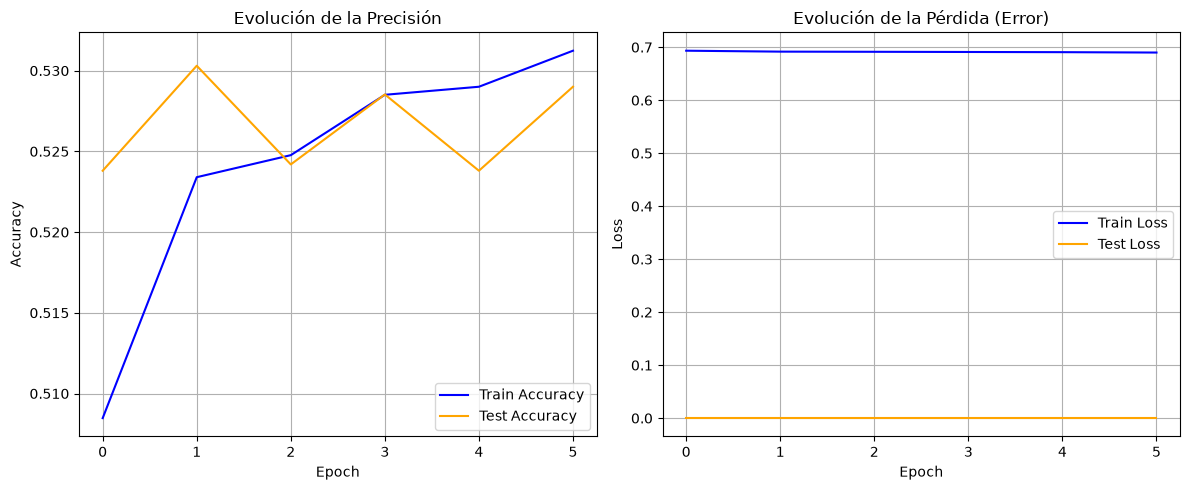

In [14]:
import matplotlib.pyplot as plt

# Graficar los resultados
plt.figure(figsize=(12, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(running_acc, label='Train Accuracy', color='blue')
plt.plot(running_test_acc_cnn, label='Test Accuracy', color='orange')
plt.title('Evolución de la Precisión')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(running_loss, label='Train Loss', color='blue')
plt.plot(running_test_loss, label='Test Loss', color='orange')
plt.title('Evolución de la Pérdida (Error)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()